# 02 · Business Overview

**Questions:** How big is the business, how fast is it growing, where does revenue come from, and
is operational quality keeping up with growth?

Data: `analysis.kpi_monthly`, `analysis.category_pareto`, `marts.fact_orders` (analysis window Jan 2017 – Aug 2018; revenue = delivered orders, items + freight, BRL).

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from ecom import viz
from ecom.db import query, table

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [ ]:
kpi = query("""
    SELECT
        sum(order_value) FILTER (WHERE is_delivered)                  AS revenue,
        count(*)                                                      AS orders,
        count(DISTINCT customer_unique_id)                            AS customers,
        sum(order_value) FILTER (WHERE is_delivered)
            / count(*) FILTER (WHERE is_delivered)                    AS aov,
        100 * avg(is_late::INT) FILTER (WHERE is_delivered)           AS late_pct,
        avg(review_score)                                             AS avg_review,
        sum(order_value) FILTER (WHERE order_status IN ('canceled', 'unavailable')) AS lost_value
    FROM marts.fact_orders
    WHERE in_analysis_window
""")
kpi.T.rename(columns={0: "value"})

,value
revenue,"15,371,741.09"
orders,"99,092.00"
customers,"95,774.00"
aov,159.78
late_pct,6.79
avg_review,4.09
lost_value,"102,496.83"


## 1. Growth: revenue more than doubled year over year

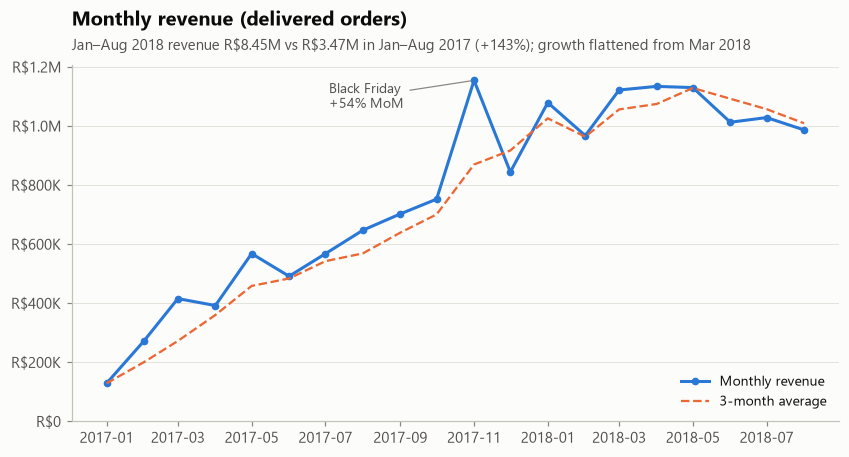

In [ ]:
m = table("analysis.kpi_monthly")

fig, ax = plt.subplots()
ax.plot(m["month"], m["revenue"], color=viz.BLUE, marker="o", markersize=4, label="Monthly revenue")
ax.plot(
    m["month"],
    m["revenue_3m_avg"],
    color=viz.ORANGE,
    linestyle="--",
    linewidth=1.5,
    label="3-month average",
)
peak = m.loc[m["month"] == "2017-11-01"].iloc[0]
ax.annotate(
    "Black Friday\n+54% MoM",
    (peak["month"], peak["revenue"]),
    xytext=(-95, -18),
    textcoords="offset points",
    fontsize=9,
    color=viz.INK_2,
    arrowprops=dict(arrowstyle="-", color=viz.MUTED, lw=0.8),
)
ax.yaxis.set_major_formatter(viz.BRL)
ax.set_ylim(0)
ax.set_title("Monthly revenue (delivered orders)")
viz.subtitle(
    ax,
    "Jan–Aug 2018 revenue R$8.45M vs R$3.47M in Jan–Aug 2017 (+143%); growth flattened from Mar 2018",
)
ax.legend(loc="lower right")
viz.save(fig, "revenue_trend")
plt.show()

In [ ]:
m[["month", "orders", "revenue", "aov", "revenue_mom_pct", "revenue_yoy_pct", "lost_order_pct"]]

,month,orders,revenue,aov,revenue_mom_pct,revenue_yoy_pct,lost_order_pct
0,2017-01-01,800,"127,482.37",169.98,NaN,NaN,1.63
1,2017-02-01,1780,"271,239.32",164.09,112.77,NaN,3.48
2,2017-03-01,2682,"414,330.95",162.74,52.75,NaN,2.42
3,2017-04-01,2404,"390,812.40",169.70,-5.68,NaN,1.12
4,2017-05-01,3700,"566,657.40",159.85,44.99,NaN,1.62
5,2017-06-01,3245,"490,050.37",156.32,-13.52,NaN,1.23
6,2017-07-01,4026,"566,299.08",146.25,15.56,NaN,1.99
7,2017-08-01,4331,"645,832.36",154.03,14.04,NaN,1.36
8,2017-09-01,4285,"701,077.49",168.93,8.55,NaN,1.35
9,2017-10-01,4631,"751,117.01",167.73,7.14,NaN,1.81


## 2. Quality did not keep up with peaks

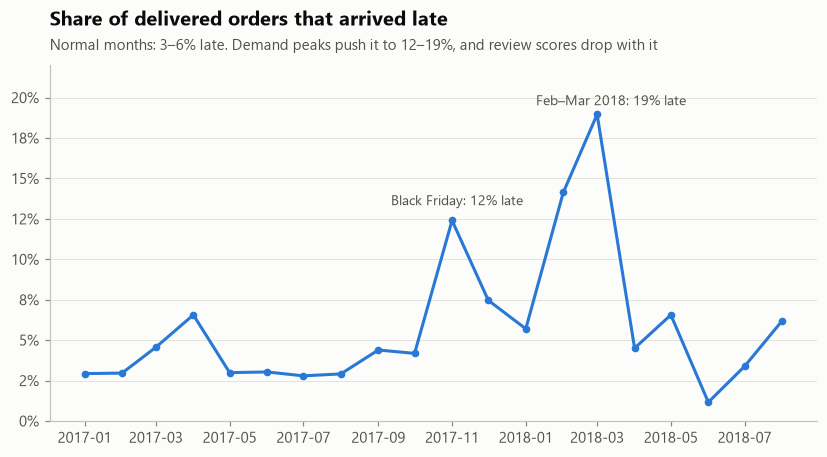

,late_pct,avg_review,avg_delivery_days
late_pct,1.00,-0.84,0.70
avg_review,-0.84,1.00,-0.92
avg_delivery_days,0.70,-0.92,1.00


In [ ]:
fig, ax = plt.subplots()
ax.plot(m["month"], m["late_pct"], color=viz.BLUE, marker="o", markersize=4)
for month, label, dy in [("2017-11-01", "Black Friday", 10), ("2018-03-01", "Feb–Mar 2018", 6)]:
    row = m.loc[m["month"] == month].iloc[0]
    ax.annotate(
        f"{label}: {row['late_pct']:.0f}% late",
        (row["month"], row["late_pct"]),
        xytext=(-40, dy),
        textcoords="offset points",
        fontsize=9,
        color=viz.INK_2,
    )
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylim(0, 22)
ax.set_title("Share of delivered orders that arrived late")
viz.subtitle(
    ax, "Normal months: 3–6% late. Demand peaks push it to 12–19%, and review scores drop with it"
)
viz.save(fig, "late_rate_trend")
plt.show()

m[["month", "late_pct", "avg_review", "avg_delivery_days"]].corr(numeric_only=True).round(2)

The late rate and the average review move in opposite directions month to month (correlation shown above). Notebook 04 tests this at order level.

## 3. When do customers buy?

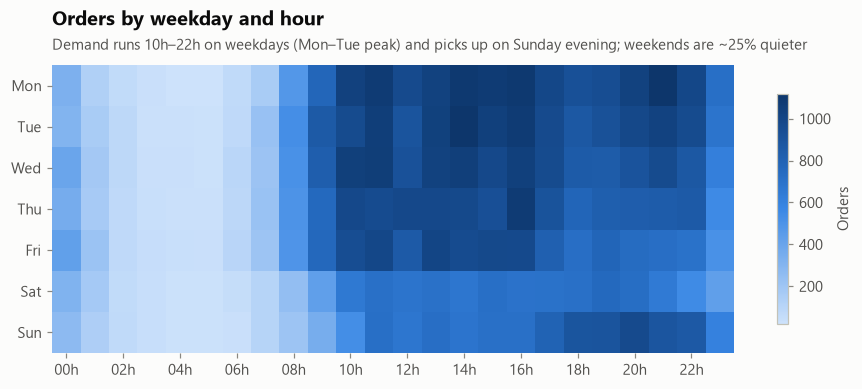

In [ ]:
when = query("""
    SELECT isodow(order_purchase_timestamp) AS dow, hour(order_purchase_timestamp) AS hour, count(*) AS orders
    FROM marts.fact_orders WHERE in_analysis_window GROUP BY ALL
""").pivot(index="dow", columns="hour", values="orders")

fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(when, aspect="auto", cmap=viz.SEQ_CMAP)
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2), [f"{h:02d}h" for h in range(0, 24, 2)])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Orders")
ax.set_title("Orders by weekday and hour")
viz.subtitle(
    ax,
    "Demand runs 10h–22h on weekdays (Mon–Tue peak) and picks up on Sunday evening; weekends are ~25% quieter",
)
viz.save(fig, "orders_heatmap")
plt.show()

## 4. Where revenue comes from

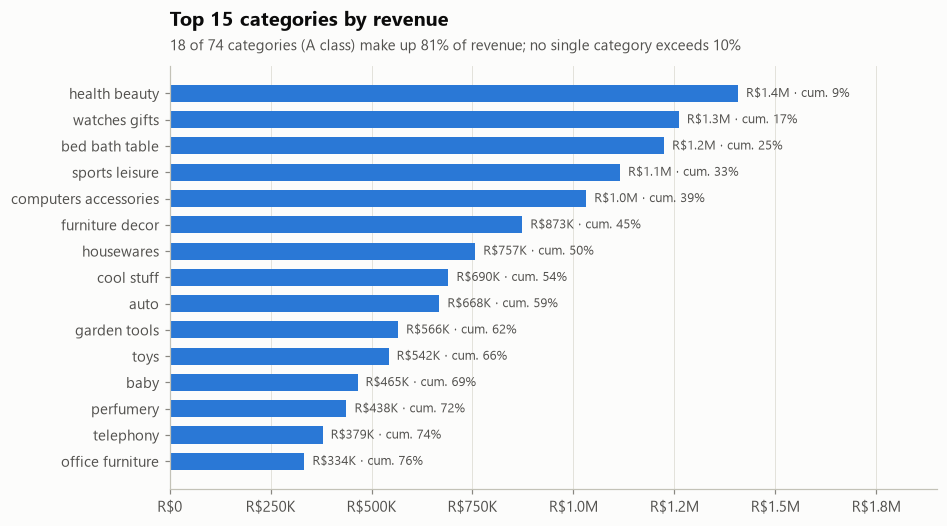

,categories,revenue_share_pct
abc_class,,
A,18,81.33
B,16,13.84
C,40,4.86


In [ ]:
p = table("analysis.category_pareto")
top = p.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["product_category"].str.replace("_", " "), top["revenue"], color=viz.BLUE, height=0.65)
for y, (rev, cum) in enumerate(zip(top["revenue"], top["cumulative_share_pct"])):
    ax.text(
        rev, y, f"  {viz.brl(rev)} · cum. {cum:.0f}%", va="center", fontsize=8.5, color=viz.INK_2
    )
ax.xaxis.set_major_formatter(viz.BRL)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(0, top["revenue"].max() * 1.35)
ax.set_title("Top 15 categories by revenue")
viz.subtitle(
    ax, "18 of 74 categories (A class) make up 81% of revenue; no single category exceeds 10%"
)
viz.save(fig, "category_pareto")
plt.show()

p.groupby("abc_class").agg(
    categories=("product_category", "size"), revenue_share_pct=("revenue_share_pct", "sum")
)

In [ ]:
query("""
    SELECT main_payment_type, count(*) AS orders,
           round(100 * count(*) / sum(count(*)) OVER (), 1) AS share_pct,
           round(avg(installments), 1) AS avg_installments,
           round(avg(order_value), 2) AS aov
    FROM marts.fact_orders WHERE is_delivered AND in_analysis_window
    GROUP BY 1 ORDER BY 2 DESC
""")

,main_payment_type,orders,share_pct,avg_installments,aov
0,credit_card,72612,75.50,3.50,166.09
1,boleto,19140,19.90,1.00,144.32
2,voucher,2970,3.10,1.10,114.86
3,debit_card,1481,1.50,1.00,140.33


## Findings

1. **Strong but slowing growth.** Jan–Aug 2018 revenue is **+143%** year over year, but monthly revenue has been flat at ~R$1.0–1.1M since March 2018.
   The next growth lever is retention and conversion, not only acquisition (see notebook 03).
2. **Peaks break operations.** The late rate jumps from 3–6% to **12% (Nov 2017)** and **14–19% (Feb–Mar 2018)**, and average review drops to 3.75★.
3. **Diversified catalogue.** The top category is only 9% of revenue; 18 categories make up 81%. Category risk is low.
4. **Credit card in installments dominates** (75% of orders, 3.5 installments on average). Boleto (bank slip) is 20%.
   Installment financing is a key conversion tool in Brazil.
5. R$102K of order value was **lost to canceled or unavailable orders** (~0.7% of revenue). This is small; it is not where the money is.

## Recommendations

- **Capacity planning for peaks:** pre-book carrier capacity and extend promised dates *selectively* for November and post-holiday months.
- **Time campaigns and CRM sends for weekdays 10h–22h, plus Sunday evening**, when customers are already shopping.